OPTIMAL SPRING DESIGN
----------------------
Wire Diameter: 0.05460577696341434
Mean Coil Diameter: 0.4305828291995179
Number of Active Coils: 8.0
Minimum Spring Weight: 0.012839079522350309
Best Fitness Value: 0.012839079522350309


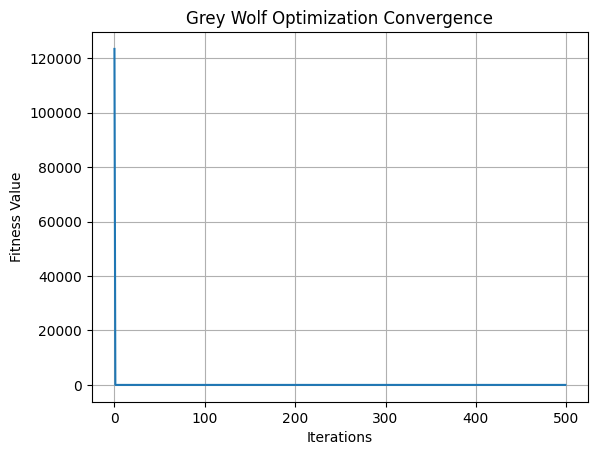

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

dim = 3
wolves = 40
iterations = 500

lb = np.array([0.05, 0.25, 2])
ub = np.array([2.0, 1.3, 15])

def objective(x):

    d, D, N = x
    N = round(N)

    weight = (N + 2) * D * d**2

    g1 = 1 - (D**3 * N) / (71785 * d**4)

    g2 = ((4 * D**2 - d * D) /
          (12566 * (D * d**3 - d**4))
          + 1 / (5108 * d**2) - 1)

    g3 = 1 - (140.45 * d) / (D**2 * N)

    g4 = (d + D) / 1.5 - 1

    penalty = 1000000 * (
        max(0, g1)**2 +
        max(0, g2)**2 +
        max(0, g3)**2 +
        max(0, g4)**2
    )

    return weight + penalty

positions = np.random.uniform(
    lb, ub, (wolves, dim)
)

alpha_pos = np.zeros(dim)
beta_pos = np.zeros(dim)
delta_pos = np.zeros(dim)

alpha_score = float('inf')
beta_score = float('inf')
delta_score = float('inf')

convergence = []

for t in range(iterations):

    for i in range(wolves):

        positions[i] = np.clip(
            positions[i], lb, ub
        )

        fitness = objective(positions[i])

        if fitness < alpha_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = alpha_score
            beta_pos = alpha_pos.copy()

            alpha_score = fitness
            alpha_pos = positions[i].copy()

        elif fitness < beta_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = fitness
            beta_pos = positions[i].copy()

        elif fitness < delta_score:

            delta_score = fitness
            delta_pos = positions[i].copy()

    a = 2 - 2 * t / iterations

    for i in range(wolves):

        for j in range(dim):

            r1 = np.random.random()
            r2 = np.random.random()

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(
                C1 * alpha_pos[j] - positions[i, j]
            )

            X1 = alpha_pos[j] - A1 * D_alpha

            r1 = np.random.random()
            r2 = np.random.random()

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(
                C2 * beta_pos[j] - positions[i, j]
            )

            X2 = beta_pos[j] - A2 * D_beta

            r1 = np.random.random()
            r2 = np.random.random()

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(
                C3 * delta_pos[j] - positions[i, j]
            )

            X3 = delta_pos[j] - A3 * D_delta

            positions[i, j] = (X1 + X2 + X3) / 3

    convergence.append(alpha_score)

best = alpha_pos.copy()
best[2] = round(best[2])

print("OPTIMAL SPRING DESIGN")
print("----------------------")

print("Wire Diameter:", best[0])
print("Mean Coil Diameter:", best[1])
print("Number of Active Coils:", best[2])

print("Minimum Spring Weight:",
      (best[2] + 2) * best[1] * best[0]**2)

print("Best Fitness Value:", alpha_score)

plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Fitness Value")
plt.title("Grey Wolf Optimization Convergence")
plt.grid()
plt.show()